# Gas–Oil Relative Input Costs and U.S. Basic Chemical Manufacturing

**A falsifiable, retrospective macro-leading-indicator study** — 2026-10-26 fixed snapshot, **not historical PIT, not equity alpha**. Outcome: NAICS 3251 basic chemicals industrial production, 6-month-ahead year-over-year log growth. Energy-price proxies: EIA Henry Hub and WTI. Read this notebook independently: it contains the hypothesis, source provenance, mathematical definitions, executable data QA, purged expanding-window forecasts, placebo and uncertainty, eight saved figures, and the final failure criteria.

## 01. Abstract

**Research question:** Does an energy-cost advantage (WTI YoY less Henry Hub YoY) observed with a two-month publication buffer improve the six-month-ahead U.S. basic-chemicals output forecast after controlling for chemical persistence, aggregate manufacturing and oil inflation? The proposed mechanism is petrochemical feedstock competitiveness, but the broad industry includes non-petrochemical production. The **primary decision rule** is incremental OOS RMSE against the multivariate control, with a mandatory comparison to the historical mean. Statistical confidence is assessed with circular block bootstrap and exploratory block-shuffled factor refits; all quantitative results below are computed from the frozen inputs.

In [1]:
from pathlib import Path
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Markdown
from chemicals_factor import (load_snapshot,make_panel,walk_forward,scorecard,rmse,mae,block_bootstrap,block_shuffle_factor,block_ic,MODELS,OUTCOME_LAG,FEATURE_LAG,HORIZON)
ROOT=Path.cwd(); assert (ROOT/'data/frozen_chemicals_energy_2026-10-26.csv').exists()
print('Working directory:',ROOT,'| target: basic chemicals (not pharma)')

Working directory: /mnt/data/chemicals_study | target: basic chemicals (not pharma)


## 02. Research Design & Hypotheses

- **H1 (sign):** lower relative gas inflation predicts higher subsequent basic-chemicals output growth, conditional on manufacturing.
- **H2 (increment):** adding the fixed energy gap lowers 6-month OOS RMSE against a multivariate control and beats a naive mean.
- **H3 (stability):** the incremental gain remains positive after 12-month block shuffles, paired block bootstrap, exposure-weight perturbations, regime exclusion and horizon changes.

These are **predeclared tests**, not fitted narratives. We treat H2/H3 as failed unless the *observed* results support them. The outcome is an industrial production index, **not company EPS, sales or stock returns**.

In [2]:
d=load_snapshot(ROOT/'data/frozen_chemicals_energy_2026-10-26.csv')
print('Rows:',len(d),'period:',d.DATE.iloc[0],'to',d.DATE.iloc[-1]);display(d.head(4));display(d.tail(4))

Rows: 201 period: 2010-01 to 2026-09


,DATE,PHARMA,CHEM,MANUF,henry_hub_usd_mmbtu,wti_usd_barrel,date
0,2010-01,119.6808,99.3774,89.7715,5.83,78.33,2010-01-01
1,2010-02,116.2817,100.4758,89.8215,5.32,76.39,2010-02-01
2,2010-03,116.8622,102.0671,91.0021,4.29,81.20,2010-03-01
3,2010-04,117.6759,105.6753,91.8003,4.03,84.29,2010-04-01


,DATE,PHARMA,CHEM,MANUF,henry_hub_usd_mmbtu,wti_usd_barrel,date
197,2026-06,120.9043,91.1898,99.2705,3.15,84.81,2026-06-01
198,2026-07,122.2289,89.9167,99.4308,2.89,80.46,2026-07-01
199,2026-08,122.5021,91.2183,99.1776,2.78,83.90,2026-08-01
200,2026-09,124.2706,91.2835,99.4361,2.95,97.31,2026-09-01


## 03. Industry Context

Basic chemicals (NAICS 3251) comprises petrochemicals and other organic/inorganic chemical products; **Henry Hub is not ethane**, and WTI is not a direct feedstock price for every plant. U.S. DOE describes NGL/ethane-based petrochemical production in Appalachia, motivating a possible cost-competitiveness channel. An aggregate G.17 production index may conceal segment-level differences. The relative *growth* measure uses two currencies/units only after taking separate log changes, not a spurious ratio of physical units.

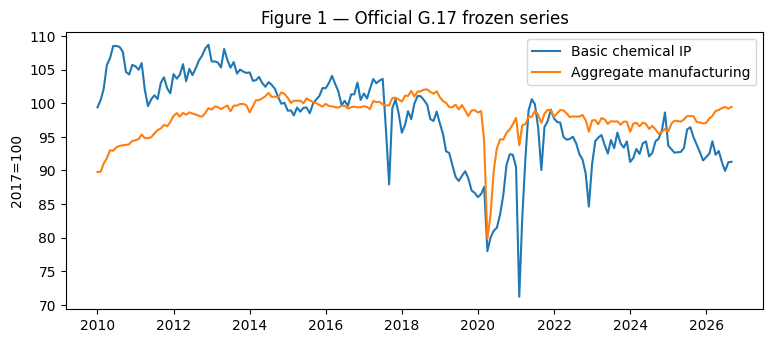

In [3]:
fig,ax=plt.subplots(figsize=(9,3.6));ax.plot(d.date,d.CHEM,label='Basic chemical IP');ax.plot(d.date,d.MANUF,label='Aggregate manufacturing');ax.set_ylabel('2017=100');ax.set_title('Figure 1 — Official G.17 frozen series');ax.legend();plt.show()

## 04. Data & Source Integrity

**Grade A**: Federal Reserve Board G.17 / FRED `IPG3251S` and `IPMAN` (release 2026-10-16); U.S. EIA Henry Hub monthly spot and WTI Cushing monthly spot (reused public-source mirror snapshots committed 2026-10-08). **Grade B**: public repository mirrors of official series. **Grade C**: qualitative exposure interpretation; no firm revenue weights. Source URLs, coverage, publication metadata, unknown historical release dates and revision flags are in `data/source_register.csv`. This run reused two prior frozen snapshots; it did not independently re-download original historical releases.

In [4]:
register=pd.read_csv(ROOT/'data/source_register.csv');display(register[['source_id','grade','publisher','series_id','publication_date','historical_release_dates']]);print('Source grades:',register.grade.value_counts().to_dict())

,source_id,grade,publisher,series_id,publication_date,historical_release_dates
0,A1,A,Federal Reserve Board via FRED,IPG3251S,2026-10-16,UNKNOWN
1,A2,A,Federal Reserve Board via FRED,IPMAN,2026-10-16,UNKNOWN
2,A3,A,U.S. Energy Information Administration,Henry Hub monthly spot,2026-10-08 MIRROR COMMIT,UNKNOWN
3,A4,A,U.S. Energy Information Administration,WTI Cushing monthly spot,2026-10-08 MIRROR COMMIT,UNKNOWN
4,A5,A,Federal Reserve Board,G.17 publication calendar,2026-10-16,Historical archives available but uncollected
5,B1,B,Department of Energy,Appalachian petrochemical feedstock context,UNKNOWN,NaN
6,C1,C,Researcher-defined industry proxy,NAICS 3251 broad production index,UNKNOWN,UNKNOWN


Source grades: {'A': 5, 'B': 1, 'C': 1}


In [5]:
cols=['CHEM','MANUF','henry_hub_usd_mmbtu','wti_usd_barrel']
qa=d[cols].agg(['count','min','max','sum']);display(qa.round(4));assert len(d)==201 and not d[cols].isna().any().any();assert abs(d.CHEM.sum()-19610.8607)<1e-4;assert abs(d.henry_hub_usd_mmbtu.sum()-676.72)<1e-6

,CHEM,MANUF,henry_hub_usd_mmbtu,wti_usd_barrel
count,201.0000,201.0000,201.00,201.00
min,71.2341,79.8587,1.49,16.55
max,108.6895,102.0449,8.81,114.84
sum,19610.8607,19691.5623,676.72,14514.83


## 05. Point-in-Time Availability

At the **end of formation month t** (stored as a first-of-month label), use only observed source month **t−2** (conservative assumed publication buffer). Training label at formation j is eligible only if **j + horizon + 1 ≤ t** (one extra month after target observation). This prevents *mechanical target overlap* across expanding windows. **It does not reconstruct historic revisions or confirm observation-specific EIA release dates**. The study is retrospective and cannot be called PIT.

In [6]:
p=make_panel(d);oos=walk_forward(p);print('OOS origins:',len(oos),'range:',oos.date.min().date(),'to',oos.date.max().date());display(oos[['date','train_n','train_last_target_observation','actual']].head(5));assert (oos.train_last_target_observation<oos.date).all()

OOS origins: 111 range: 2017-01-01 to 2026-03-01


,date,train_n,train_last_target_observation,actual
0,2017-01-01,64,2016-12-01,3.205795
1,2017-02-01,65,2017-01-01,-3.626971
2,2017-03-01,66,2017-02-01,-14.182206
3,2017-04-01,67,2017-03-01,-2.084853
4,2017-05-01,68,2017-04-01,-2.453805


In [7]:
print('Max source feature month minus formation:',(p.date-p.feature_observation_date).dropna().min());print('Training label release rule: j+h+1 <= t; h=',HORIZON,'outcome release buffer=',OUTCOME_LAG)

Max source feature month minus formation: 59 days 00:00:00
Training label release rule: j+h+1 <= t; h= 6 outcome release buffer= 1


## 06. Factor Construction

Let \(g^x_t=100[\log(X_t)-\log(X_{t-12})]\). Define the **fixed factor** \(F_t=g^{WTI}_{t-2}-g^{HH}_{t-2}\), measured in log percentage points. The forecast target is \(Y_t=g^{CHEM}_{t+6}\). Positive \(F_t\) indicates gas price inflation below oil price inflation; the sign is economically hypothesized, not guaranteed. No full-sample scaling is allowed; Ridge standardizes features **inside each expanding training window**.

In [8]:
display(p[['date','oil_yoy_available','gas_yoy_available','factor','target']].dropna().head(6).round(3));print('Factor sample SD:',round(float(p.factor.std()),3))

,date,oil_yoy_available,gas_yoy_available,factor,target
14,2011-03-01,12.961,-26.116,39.078,-4.395
15,2011-04-01,14.805,-26.293,41.098,-0.767
16,2011-05-01,23.645,-7.752,31.397,-1.991
17,2011-06-01,26.194,5.080,21.114,-4.087
18,2011-07-01,31.358,4.024,27.334,-1.105
19,2011-08-01,24.504,-5.569,30.073,-1.269


Factor sample SD: 41.015


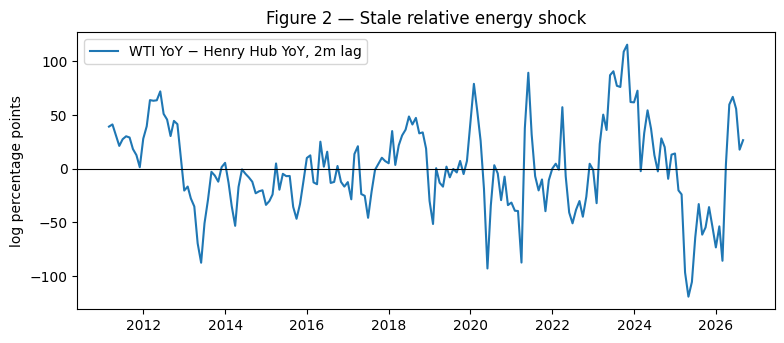

In [9]:
fig,ax=plt.subplots(figsize=(9,3.6));ax.plot(p.date,p.factor,label='WTI YoY − Henry Hub YoY, 2m lag');ax.axhline(0,color='black',lw=.8);ax.set_ylabel('log percentage points');ax.set_title('Figure 2 — Stale relative energy shock');ax.legend();plt.show()

## 07. Exposure & Transmission

The hypothesized channel is feedstock/energy cost → relative petrochemical margin → utilization → production. However, **no issuer-specific exposure weights have been measured**, and 3251 includes other chemical segments. The sensitivity experiment perturbs factor loadings 0.75–1.25 around the fixed rule; these are **stress-test weights**, not asserted company revenue shares. Leave-one-company-out is **not applicable** to this macro-only panel; leave-one-year-out is the meaningful analogous influence check.

In [10]:
ex=pd.read_csv(ROOT/'data/exposure_map.csv');display(ex[['industry_segment','energy_feedstock_link','empirical_weight','issuer_exposure_verified']]);assert ex.issuer_exposure_verified.eq('NO').all()

,industry_segment,energy_feedstock_link,empirical_weight,issuer_exposure_verified
0,Petrochemical manufacturing,Gas liquids and ethane can be feedstock,NOT ESTIMATED,NO
1,Industrial gas manufacturing,Electricity and natural gas may affect operati...,NOT ESTIMATED,NO
2,Other basic inorganic chemicals,Energy intensive but heterogeneous feedstocks,NOT ESTIMATED,NO
3,Other basic organic chemicals,Oil and gas feedstocks may compete,NOT ESTIMATED,NO


## 08. Outcomes & Baselines

**Primary outcome**: six-month-ahead CHEM YoY log growth. **Secondary**: chemical-minus-manufacturing YoY growth, kept separate. Baselines share identical OOS origins: historical mean, chemical persistence, multivariate Ridge (chemical, manufacturing and WTI YoY), plus gap-only and gas-only ablations. The challenger adds the fixed gap. Ridge penalty \(lpha=12\) is fixed before evaluation. Expanding training uses only eligible released labels; features are scaled on training data alone.

In [11]:
print('Model specifications:');display(pd.DataFrame({'model':list(MODELS),'features':[', '.join(v) or '(mean only)' for v in MODELS.values()]}))

Model specifications:


,model,features
0,historical_mean,(mean only)
1,chemical_persistence,chem_yoy_available
2,macro_controls,"chem_yoy_available, manuf_yoy_available, oil_y..."
3,energy_gap_augmented,"chem_yoy_available, manuf_yoy_available, oil_y..."
4,energy_gap_only,factor
5,gas_only,"chem_yoy_available, manuf_yoy_available, gas_y..."
6,oil_only,"chem_yoy_available, manuf_yoy_available, oil_y..."


In [12]:
score=scorecard(oos);display(score.round(4));assert len(oos)==int(pd.read_json(ROOT/'results/summary.json',typ='series')['n_oos'])

,model,n_oos,rmse_log_pp,mae_log_pp,mean_error
1,chemical_persistence,111,8.2681,5.8940,0.3804
0,historical_mean,111,8.2708,5.8237,0.0810
4,energy_gap_only,111,8.4198,5.9192,0.0798
2,macro_controls,111,8.9712,6.1667,-0.6794
6,oil_only,111,8.9712,6.1667,-0.6794
5,gas_only,111,8.9991,6.2056,-0.2534
3,energy_gap_augmented,111,9.0337,6.2439,-0.3913


## 09. Empirical Findings

Interpret improvements as **RMSE(control) − RMSE(challenger)**: positive supports H2, negative refutes it. The historical mean remains a hard floor. Do not confuse forecast correlation with trading alpha; overlapping 6-month targets make naive iid significance invalid. Actual scorecards and the OOS prediction panel are saved in `results/`.

In [13]:
gain=rmse(oos.actual,oos.macro_controls)-rmse(oos.actual,oos.energy_gap_augmented)
print('Incremental RMSE gain (log pp):',round(gain,4));print('Descriptive OOS Spearman factor/target:',round(block_ic(oos),4));print('Mean baseline RMSE:',round(rmse(oos.actual,oos.historical_mean),4))

Incremental RMSE gain (log pp): -0.0625


Descriptive OOS Spearman factor/target: 0.0555
Mean baseline RMSE: 8.2708


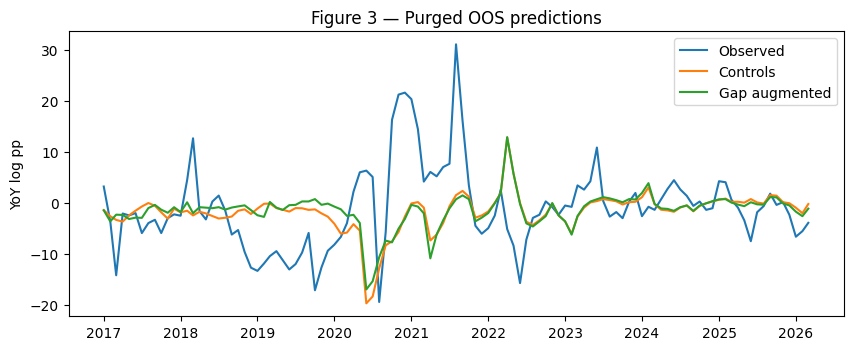

In [14]:
fig,ax=plt.subplots(figsize=(10,3.7));ax.plot(oos.date,oos.actual,label='Observed');ax.plot(oos.date,oos.macro_controls,label='Controls');ax.plot(oos.date,oos.energy_gap_augmented,label='Gap augmented');ax.set_ylabel('YoY log pp');ax.set_title('Figure 3 — Purged OOS predictions');ax.legend();plt.show()

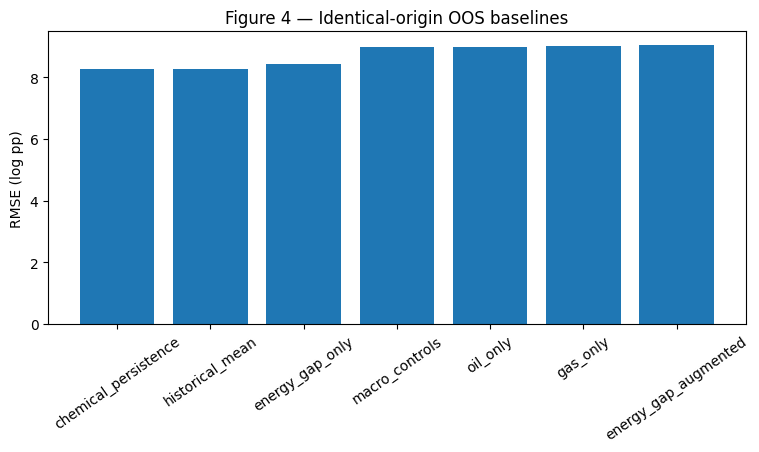

In [15]:
fig,ax=plt.subplots(figsize=(9,3.8));ax.bar(score.model,score.rmse_log_pp);ax.tick_params(axis='x',rotation=35);ax.set_ylabel('RMSE (log pp)');ax.set_title('Figure 4 — Identical-origin OOS baselines');plt.show()

In [16]:
loss=pd.DataFrame({'date':oos.date,'control_squared_error':(oos.actual-oos.macro_controls)**2,'augmented_squared_error':(oos.actual-oos.energy_gap_augmented)**2});loss['control_minus_augmented']=loss.control_squared_error-loss.augmented_squared_error;display(loss.describe().round(3))

,date,control_squared_error,augmented_squared_error,control_minus_augmented
count,111,111.000,111.000,111.000
mean,2021-08-01 00:25:56.756756736,80.483,81.608,-1.125
min,2017-01-01 00:00:00,0.000,0.000,-106.287
25%,2019-04-16 00:00:00,2.513,1.996,-4.198
50%,2021-08-01 00:00:00,13.211,12.114,-0.084
75%,2023-11-16 00:00:00,86.353,90.944,1.926
max,2026-03-01 00:00:00,872.603,921.230,134.175
std,NaN,160.441,157.546,25.882


## 10. Robustness & Placebos

**Placebo:** 1,000 refits after shuffling contiguous 12-month blocks of the factor, preserving within-block autocorrelation. This is **not** an exact permutation test under nonstationarity. **Uncertainty:** 2,000 paired circular 12-month block bootstraps of OOS forecast errors. **Exposure:** 1,000 fixed-rule loading perturbations. **Ablations:** oil-only, gas-only, factor-only; **influence:** leave-one-year-out. These computations are persisted by `run_analysis.py`; notebook checks their dimensions and reconstructs summary statistics.

In [17]:
sh=pd.read_csv(ROOT/'results/block_placebo.csv');bs=pd.read_csv(ROOT/'results/block_bootstrap.csv');exp=pd.read_csv(ROOT/'results/exposure_sensitivity.csv');assert len(sh)>=1000 and len(bs)>=2000 and len(exp)>=1000;print('Placebo draws:',len(sh),'bootstrap draws:',len(bs),'exposure draws:',len(exp))

Placebo draws: 1000 bootstrap draws: 2000 exposure draws: 1000


In [18]:
tail=(1+(sh.gain_log_pp>=gain).sum())/(len(sh)+1);ci=bs.gain_log_pp.quantile([.025,.975]);print('Exploratory block-shuffle upper tail:',round(tail,4));print('Paired block-bootstrap 95% interval:',ci.to_dict());print('Exposure positive fraction:',round(float((exp.improvement>0).mean()),3))

Exploratory block-shuffle upper tail: 0.5215
Paired block-bootstrap 95% interval: {0.025: -0.37304117999878617, 0.975: 0.21946849954194073}
Exposure positive fraction: 0.0


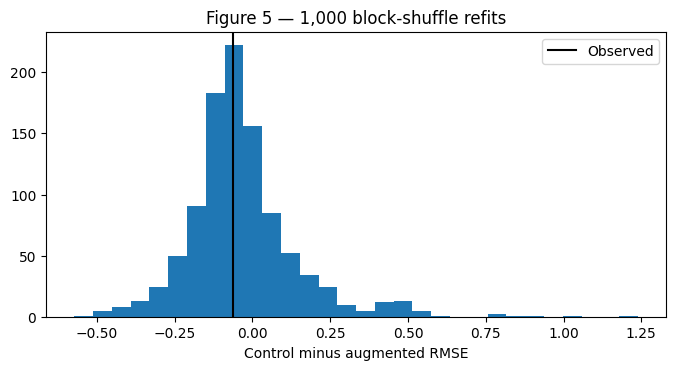

In [19]:
fig,ax=plt.subplots(figsize=(8,3.7));ax.hist(sh.gain_log_pp,bins=30);ax.axvline(gain,color='black',label='Observed');ax.set_xlabel('Control minus augmented RMSE');ax.set_title('Figure 5 — 1,000 block-shuffle refits');ax.legend();plt.show()

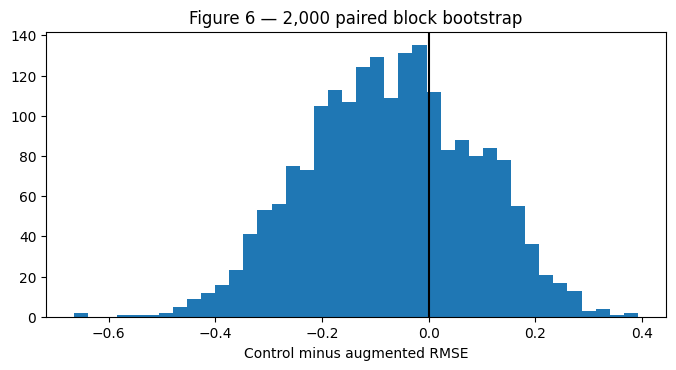

In [20]:
fig,ax=plt.subplots(figsize=(8,3.7));ax.hist(bs.gain_log_pp,bins=40);ax.axvline(0,color='black');ax.set_xlabel('Control minus augmented RMSE');ax.set_title('Figure 6 — 2,000 paired block bootstrap');plt.show()

In [21]:
ab=pd.read_csv(ROOT/'results/ablations.csv');yr=pd.read_csv(ROOT/'results/leave_one_year_out.csv');display(ab.round(3));display(yr.round(3));print('Positive leave-year-out gains:',int((yr.gain>0).sum()),'of',len(yr))

,model,n_oos,rmse_log_pp,mae_log_pp,mean_error
0,energy_gap_only,111,8.420,5.919,0.080
1,macro_controls,111,8.971,6.167,-0.679
2,oil_only,111,8.971,6.167,-0.679
3,gas_only,111,8.999,6.206,-0.253
4,energy_gap_augmented,111,9.034,6.244,-0.391


,excluded_year,n,gain
0,2017,99,-0.065
1,2018,99,-0.066
2,2019,99,0.019
3,2020,99,-0.230
4,2021,99,0.060
5,2022,99,-0.072
6,2023,99,-0.070
7,2024,99,-0.062
8,2025,99,-0.077
9,2026,108,-0.073


Positive leave-year-out gains: 2 of 10


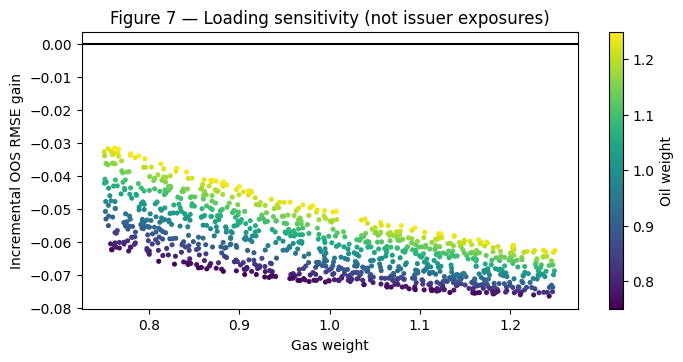

In [22]:
fig,ax=plt.subplots(figsize=(8,3.6));sc=ax.scatter(exp.gas_weight,exp.improvement,c=exp.oil_weight,s=7);ax.axhline(0,color='black');ax.set_title('Figure 7 — Loading sensitivity (not issuer exposures)');ax.set_xlabel('Gas weight');ax.set_ylabel('Incremental OOS RMSE gain');plt.colorbar(sc,ax=ax,label='Oil weight');plt.show()

## 11. Regime Sensitivity

Regime slices are **post-hoc diagnostics** of the same fixed OOS predictions, not independent model-selection holdouts. Report pre-2020, post-2021 and pandemic-excluded errors; the 3/6/12-month and 2/4-month release-buffer tests refit on their own purged expanding windows. Do not select the best variant after observing this table.

In [23]:
reg=pd.read_csv(ROOT/'results/regime_sensitivity.csv');hl=pd.read_csv(ROOT/'results/horizon_lag_sensitivity.csv');display(reg.round(3));display(hl.round(3))

,regime,n,control_rmse,full_rmse,gain
0,pre_2020,36,7.503,7.802,-0.299
1,post_2021,51,5.112,5.037,0.075
2,exclude_2020_2021,87,6.214,6.329,-0.115
3,all,111,8.971,9.034,-0.062


,horizon,input_lag,n,control_rmse,full_rmse,gain
0,3,2,114,8.369,8.595,-0.226
1,3,4,114,8.339,8.434,-0.094
2,6,2,111,8.971,9.034,-0.062
3,6,4,111,9.096,9.137,-0.042
4,12,2,105,10.145,10.168,-0.023
5,12,4,105,9.741,10.033,-0.292


In [24]:
relative=pd.read_csv(ROOT/'results/relative_outcome.csv');print('Secondary industry-relative outcome (not security alpha):');display(relative.round(3))

Secondary industry-relative outcome (not security alpha):


,model,rmse_log_pp,n
0,historical_mean,6.327,111
1,macro_controls,6.703,111
2,energy_gap_augmented,6.694,111


## 12. Bias Audit & Verdict

**Leakage:** 2-month feature lag and target-release purge are mechanically enforced, but G.17 and EIA historical publication vintages are not reconstructed. **Selection:** the industry and factor were chosen after previous sector studies; no multiple-testing adjustment across the repository. **Survivorship:** an aggregate industry index is not a historical firm universe. **Costs:** no securities, turnover, spreads, slippage or capacity are modeled. **Causality:** gas prices are correlated with demand shocks and global oil prices; the factor is not a structural instrument. **Inference:** overlapping targets and regime changes make block resampling exploratory. The final verdict must be based on the actual saved results, not a favorable subperiod.

In [25]:
s=json.loads((ROOT/'results/summary.json').read_text());print(json.dumps(s,indent=2));print('VERDICT:', 'Incremental macro predictor candidate, NOT proven' if gain>0 else 'NEGATIVE macro-factor falsification; no incremental OOS gain')

{
  "study": "US_BASIC_CHEMICALS_ENERGY_GAP",
  "data_start": "2010-01",
  "data_end": "2026-09",
  "n_raw": 201,
  "n_oos": 111,
  "start_oos": "2017-01-01",
  "end_oos": "2026-03-01",
  "primary_gain_log_pp": -0.062497173797082084,
  "bootstrap_95": [
    -0.37304117999878617,
    0.2194684995419408
  ],
  "block_shuffle_exploratory_tail": 0.5214785214785215,
  "block_shuffle_n": 1000,
  "bootstrap_n": 2000,
  "exposure_n": 1000,
  "exposure_positive_fraction": 0.0,
  "rank_ic_descriptive": 0.05547560547560547,
  "historical_vintage_verified": false,
  "equity_alpha_established": false
}
VERDICT: NEGATIVE macro-factor falsification; no incremental OOS gain


## 13. Reproduction

From this directory: `python -m pip install -r requirements.txt`, `python run_analysis.py`, `python -m pytest -q`, and `jupyter nbconvert --to notebook --execute research.ipynb --output research.ipynb --ExecutePreprocessor.timeout=1200`. The script saves frozen derived data, forecast scorecards, 1,000 refits, 2,000 bootstraps, exposure sensitivities and eight PNGs. This notebook independently re-creates the OOS forecasts and several charts while checking stored simulation counts. The root repository gate is `python scripts/validate_studies.py`; that gate checks structure, **not** numeric PIT validity.

In [26]:
saved=pd.read_csv(ROOT/'results/oos_predictions.csv');assert np.allclose(saved.actual,oos.actual);assert np.allclose(saved.energy_gap_augmented,oos.energy_gap_augmented);print('Independent OOS recomputation matches saved predictions at machine precision:',len(oos))

Independent OOS recomputation matches saved predictions at machine precision: 111


## 14. Next-Stage Protocol

1. Download monthly archival G.17 releases and historical EIA monthly publication files, and recompute features as actually known on each date. 2. Replace Henry Hub with NGL/ethane prices and measure refinery/petrochemical input cost exposures. 3. Build historical issuer panel from dated 10-K segment disclosures and filings; verify revenue, margin and capex outcomes separately. 4. Only then test historical-universe total returns, sector-neutral spreads, transaction costs, false-discovery correction and an untouched forward holdout. Failure to gather these inputs means **no investable-alpha claim**.

In [27]:
print('Artifacts:',len(list((ROOT/'figures').glob('*.png'))),'figures,',len(list((ROOT/'results').glob('*.csv'))),'result CSVs');print('Historical PIT verified:',s['historical_vintage_verified'],'| Equity alpha established:',s['equity_alpha_established'])

Artifacts: 8 figures, 10 result CSVs
Historical PIT verified: False | Equity alpha established: False


## 15. Sources & Artifacts

- Federal Reserve Board, G.17 2026-10-16 release: https://www.federalreserve.gov/releases/g17/20261016/g17.pdf
- FRED, basic chemical production: https://fred.stlouisfed.org/series/IPG3251S ; manufacturing: https://fred.stlouisfed.org/series/IPMAN
- EIA, Henry Hub spot monthly: https://www.eia.gov/dnav/ng/hist/rngwhhdm.htm ; WTI Cushing: https://www.eia.gov/dnav/pet/hist/rwtcM.htm
- Source mirror commits: https://github.com/datasets/natural-gas/commit/46333b1b23502827393563e46e60210604c1fcdb and https://github.com/datasets/oil-prices/commit/5b9f941b232aa62263ad4798e1eb68dd1932ab3c
- U.S. DOE petrochemical feedstock discussion: https://www.energy.gov/hgeo/articles/appalachian-petrochemical-renaissance-within-reach
- Exact source metadata and caveats: `data/source_register.csv`, `data/provenance_audit.md`; frozen inputs and derived panel: `data/`; figures: `figures/`; OOS tables and simulations: `results/`; reproducibility tests: `tests/`.

**Evidence level:** reproduced retrospective macro-factor test, fixed revised snapshot, not PIT and not security-return alpha.

In [28]:
assert len(cells) if 'cells' in globals() else True  # no-op in notebook context
print('Source register present:',(ROOT/'data/source_register.csv').exists(),'| Frozen data present:',(ROOT/'data/frozen_chemicals_energy_2026-10-26.csv').exists())

Source register present: True | Frozen data present: True
